# Eye 외부 보조학습과 외부검증 검토

기존 종합 노트북과 별도인 후속 결과입니다. **외부학습 효과는 기존 606행에서 비교했고, 독립 화장품 EPA 외부 성능은 미검증(적격0행)**입니다. 기존 production 결과를 덮어쓰지 않았습니다.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'training_complete.json').exists()
load=lambda name: json.loads((ROOT/name).read_text(encoding='utf-8'))
display(load('verification.json'))

{'passed': True,
 'new_outer_jobs_checked': 90,
 'new_full_grid_candidates_checked': 1800,
 'control_outer_jobs_checked': 90,
 'pooled_metrics_recomputed': 36,
 'same_evaluation_rows_groups_splits': True,
 'thresholds_recomputed_from_original_inner_oof': True,
 'concentration_medians_train_only': True,
 'protected_files_checked': 7612,
 'protected_files_changed': 0,
 'executed_code_teacher_aux_features_and_source_hashes_match': True,
 'eye_input_sha256': '811268d4813fcdd68e85458641bf5823239cae04e1fa871766c77e04f0221e7f',
 'cosmetic_external_evaluation_rows': 0}

## 1. 외부 관측자료와 누수 검사

STopTox GHS 라벨을 EPA 정답으로 합치지 않았습니다. CAS·표준화 구조·연결성뿐 아니라 알려진 UVCB/고분자와 로컬과 동일한 Morgan 표현을 제외했습니다. Table S4에 원시험 ID가 없어 연구 단위 독립성은 완전히 입증되지 않았습니다. [원 논문](https://pmc.ncbi.nlm.nih.gov/articles/PMC8863177/)

In [2]:
a=load('data_audit.json')
display({k:a[k] for k in ['stoptx_input_rows','training_rows','training_label_counts','excluded_union_all_reasons','common_evaluation_rows','evaluation_excluded_rows','uvcb_screen_scope']})
display(pd.read_csv(ROOT/'training_attrition_disjoint.csv'))

{'stoptx_input_rows': 3545,
 'training_rows': 3261,
 'training_label_counts': {'0': 2279, '1': 982},
 'excluded_union_all_reasons': 284,
 'common_evaluation_rows': 606,
 'evaluation_excluded_rows': 0,
 'uvcb_screen_scope': '4353 Canada prioritized CAS inventory plus explicit OECD Canada record 68955-19-1. Absence from this inventory does NOT certify a pure discrete substance.'}

,reason_in_order,newly_excluded,remaining
0,excluded_overlap,230,3315
1,excluded_invalid_standardized_parent,1,3314
2,excluded_known_uvcb_or_polymer,16,3298
3,excluded_identical_local_morgan,35,3263
4,excluded_conflicting_parent,0,3263
5,excluded_duplicate_parent,2,3261


## 2. 실제 보조학습 전달과 평가 조건

필터링된 외부 관측자료로 새 RF 성분 모델을 학습하고 고정했습니다. 성분 점수의 가중평균·최대·최소·가중표준편차를 EPA 분류기에 추가합니다. RF/XGB 사이의 가중치 전이가 아닙니다.

대조군2,269 vs 실험군2,273 특성, 같은606행·그룹·5×3 fold·20후보·threshold 규칙을 사용합니다. 수치 threshold는 각 arm의 inner OOF에서 정합니다. 증강67행은 train-only입니다. 대조군 저장 결과는 전체 후보와 cutoff를 감사하고 일부 재학습으로 점수 일치를 확인했습니다.

In [3]:
display(load('training_complete.json'))
display(load('preparation_verification.json'))

{'status': 'complete',
 'new_outer_jobs': 90,
 'reused_control_outer_jobs': 90,
 'new_candidate_jobs': 1800,
 'new_target_model_fits': 5490,
 'elapsed_seconds': 1149.7592425346375,
 'evaluation_rows_per_arm_seed': 606,
 'independent_external_evaluation_rows': 0}

{'passed': True,
 'teacher_reloaded_predictions_match': True,
 'all_673_component_pools_match': True,
 'all_606_original_rows_covered_per_seed': True,
 'heldout_groups_excluded_from_all_target_training': True,
 'control_refit_matches_saved_scores': True,
 'screened_identity_intersections': 0,
 'nearest_tanimoto_median_unique_component': 0.35714285714285715,
 'fingerprint_identical_component_count': 0,
 'note': 'Fingerprint collisions/analogs are not exact chemical identities. Domain similarity does not establish cosmetic validity.'}

## 3. 외부학습 효과: 기존 평가행에서의 paired OOF

평균과 SD는 세 seed의 결과입니다. seed 반복은 독립 연구 반복이 아니며, 최상의 seed만 선택하지 않습니다.

,label,model,control_MCC_mean,control_MCC_sd,aux_MCC_mean,aux_MCC_sd,delta_MCC_mean,delta_MCC_sd,delta_MCC_min,delta_MCC_max,positive_seed_count
0,A,lgbm,0.251454,0.037472,0.245476,0.037546,-0.005978,0.030556,-0.041087,0.014609,2
1,A,lr,0.337392,0.001210,0.342578,0.007773,0.005186,0.008982,0.000000,0.015557,1
2,A,svm,0.240446,0.038985,0.216945,0.060133,-0.023501,0.042925,-0.073017,0.003182,1
3,B,lgbm,0.211707,0.038934,0.228089,0.022259,0.016381,0.020367,-0.004297,0.036421,2
4,B,lr,0.160393,0.046295,0.156165,0.043415,-0.004228,0.007368,-0.012111,0.002484,1
5,B,svm,0.131451,0.034462,0.137997,0.031476,0.006546,0.012181,-0.004424,0.019655,2


,label,model,seed,control,stoptx_aux,delta_MCC
0,A,lgbm,42,0.272829,0.231743,-0.041087
1,A,lgbm,202,0.273347,0.287955,0.014609
2,A,lgbm,777,0.208186,0.216729,0.008543
3,A,lr,42,0.338158,0.338158,0.000000
4,A,lr,202,0.335997,0.351553,0.015557
5,A,lr,777,0.338022,0.338022,0.000000
6,A,svm,42,0.239053,0.166036,-0.073017
7,A,svm,202,0.280109,0.283292,0.003182
8,A,svm,777,0.202177,0.201508,-0.000669
9,B,lgbm,42,0.256592,0.252294,-0.004297


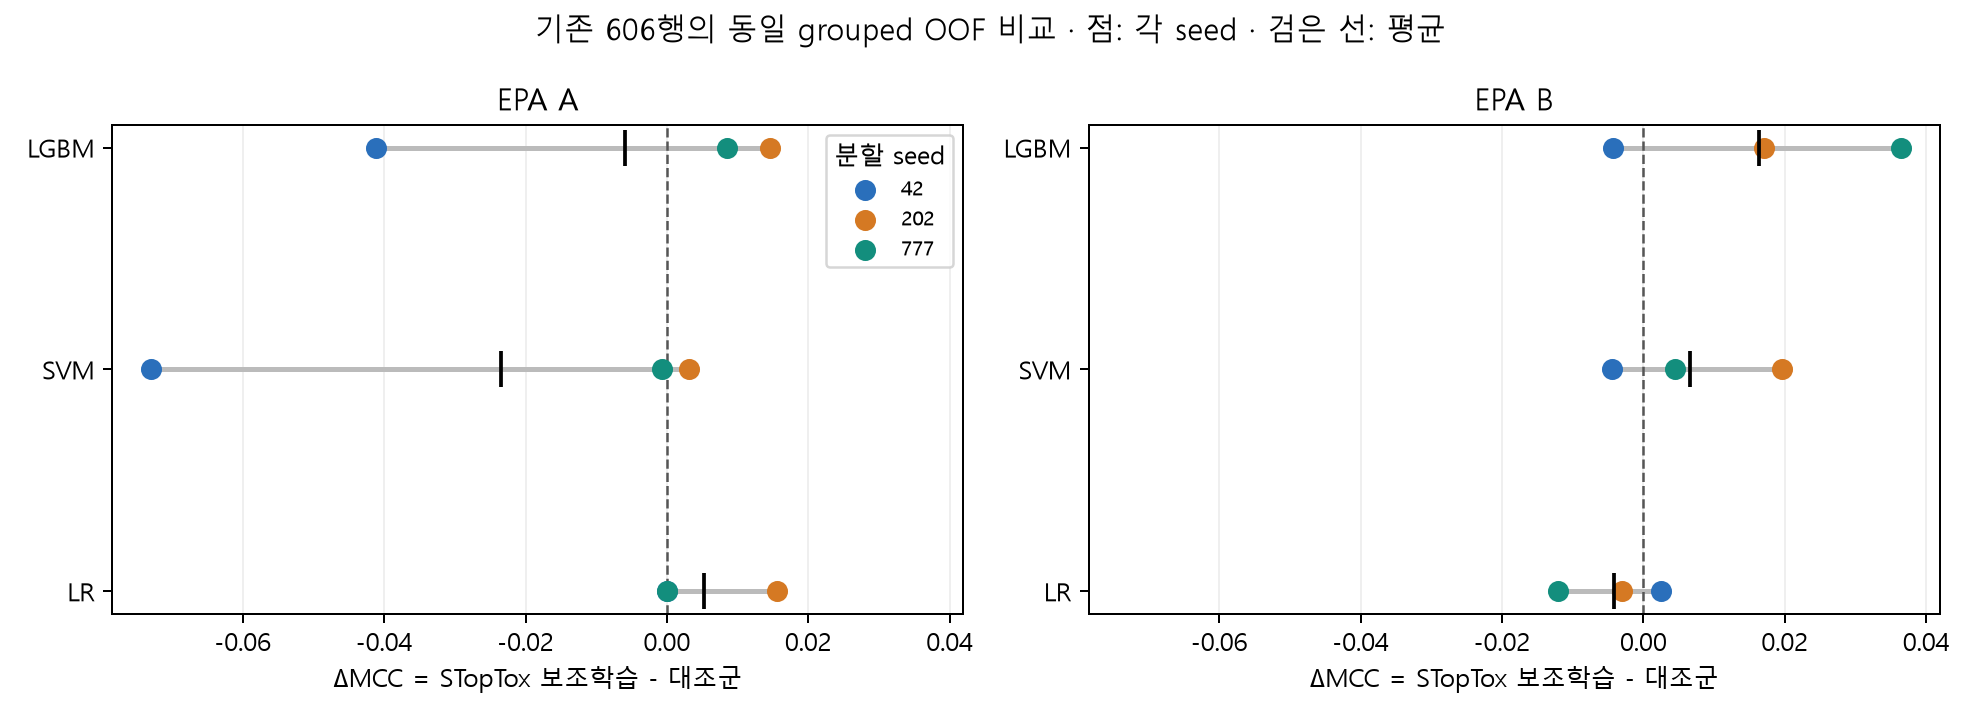

In [4]:
summary=pd.read_csv(ROOT/'paired_summary.csv')
display(summary)
display(pd.read_csv(ROOT/'paired_delta_by_seed.csv'))
display(Image(filename=str(ROOT/'paired_delta_mcc.png')))

평균 ΔMCC가 양수인 조합은 3/6, 세 seed 모두 양수인 조합은 0/6이다. 결과는 아래 모델·라벨별로 판단하며, 보조학습이 항상 개선된다는 결론은 내리지 않는다. 3개 seed는 동일 자료의 반복 분할이므로 SD는 분할 민감도이고 독립 연구 간 신뢰구간이 아니다.

In [5]:
display(pd.read_csv(ROOT/'metrics_by_seed.csv')[['arm','label','model','seed','MCC','ROC-AUC','sensitivity','specificity','PR-AUC']])

,arm,label,model,seed,MCC,ROC-AUC,sensitivity,specificity,PR-AUC
0,control,A,lgbm,42,0.272829,0.695183,0.765217,0.582485,0.394140
1,control,A,lgbm,202,0.273347,0.689710,0.686957,0.655804,0.393321
2,control,A,lgbm,777,0.208186,0.661330,0.626087,0.635438,0.311889
3,control,A,lr,42,0.338158,0.724794,0.756522,0.668024,0.400985
4,control,A,lr,202,0.335997,0.730621,0.686957,0.723014,0.386370
5,control,A,lr,777,0.338022,0.706677,0.686957,0.725051,0.338435
6,control,A,svm,42,0.239053,0.614992,0.573913,0.714868,0.268012
7,control,A,svm,202,0.280109,0.714664,0.695652,0.655804,0.378131
8,control,A,svm,777,0.202177,0.630824,0.747826,0.509165,0.261737
9,control,B,lgbm,42,0.256592,0.627883,0.665810,0.599078,0.723687


보조모델의 다음 수치는 **외부 출처 corpus의 내부 CV 진단**입니다. EPA 또는 화장품의 독립 외부 성능이 아닙니다.

In [6]:
display(load('teacher_source_internal_metrics.json'))

{'role': 'source internal diagnostic only; NOT independent external EPA/cosmetics validation',
 'n': 3261,
 'groups': 'identical binary Morgan fingerprints',
 'auc': 0.8441801036471315,
 'mcc_at_0_5': 0.49781280488372376,
 'balanced_accuracy_at_0_5': 0.7672133059395579}

## 4. 화장품 자료의 검증 적격성

[2025 논문](https://pmc.ncbi.nlm.nih.gov/articles/PMC12656482/)의 39개 제품, 58개 원료 조건, 대조군 포함6개 조합 표시행을 구별했습니다. 개체별 시험 기록·농도기준·시험액/원료 조성이 부족해 EPA 정량 검증에 쓰지 않았습니다. 원문 등급을 보존하고 임의 EPA 변환·잔량 물·범위 중간값을 만들지 않았습니다.

In [7]:
e=load('external_validation_audit.json')
display(e['decision'])
t2=pd.read_csv(ROOT/'baby_table2_observation_audit.csv')
display(t2[['test_number','ingredient_reported','supplier_reported','concentration_reported','ph_reported','original_draize_label','quantitative_external_validation_allowed']])

{'eligible_independent_EPA_external_samples': 0,
 'external_performance_computed': False,
 'case_analysis_only': True,
 'cosmetic_rows_used_for_learning_tuning_threshold': 0,
 'chemexpo': 'composition/unlabeled candidate only; no observed external Eye gold labels; no 10% rule accuracy computed',
 'author_contacted': False}

,test_number,ingredient_reported,supplier_reported,concentration_reported,ph_reported,original_draize_label,quantitative_external_validation_allowed
0,1,Decyl Glucoside,Company 1,5.00%,5.5–6.0,Slightly irritating,False
1,2,Coco-Glucoside (And) Glyceryl Oleate,Company 1,3.00%,5.5–6.0,Non-irritating,False
2,3,Lauryl Glucoside,Company 1,3.00%,5.5–6.0,Non-irritating,False
3,4,Capryl/Capramidopropyl Betaine,Company 2,2.00%,5.5–6.0,Non-irritating,False
4,5,Capryl/Capramidopropyl Betaine,Company 2,5.00%,5.5–6.0,Slightly irritating,False
5,6,Cocamidopropyl Hydroxysultaine,Company 3,1.80%,5.5–6.0,Non-irritating,False
6,7,Lauryl Hydroxysultaine,Company 4,2.40%,5.5–6.0,Mildly irritating,False
7,8,Lauryl Hydroxysultaine,Company 5,2.40%,5.5–6.0,Mildly irritating,False
8,9,Cocamide Methyl MEA,Company 5,2.00%,5.5–6.0,Non-irritating,False
9,10,Sodium PEG-7 Olive Oil Carboxylate,Company 6,1.44%,5.5–6.0,Non-irritating,False


In [8]:
display(pd.read_csv(ROOT/'baby_table3_observation_audit.csv')[['sample_id','main_pct_reported','additional_ingredient','additional_pct_reported','ph_range_reported','original_draize_label','quantitative_external_validation_allowed']])
display(pd.read_csv(ROOT/'iivs_table2_observation_audit.csv')[['formulation_id','ph','ethanol_pct_raw','glycolic_acid_pct_raw','salicylic_acid_pct_raw','bcop_ivis_reported','large_arithmetic_discrepancy','quantitative_external_validation_allowed']])

,sample_id,main_pct_reported,additional_ingredient,additional_pct_reported,ph_range_reported,original_draize_label,quantitative_external_validation_allowed
0,control,5,NaN,NaN,6.0–6.5,Slightly irritating,False
1,panthenol,5,Panthenol,1.000,6.0–7.0,Non-irritating,False
2,pq51,5,Polyquaternium-51,0.007,6.0–7.0,Slightly irritating,False
3,mg60,5,Maltooligosyl glucoside/hydrogenated starch hy...,1.480,6.0–7.0,Non-irritating,False
4,tween28,5,PEG-80 sorbitan laurate,3.500,5.5–6.0,Non-irritating,False
5,dcg,5,Disodium cocoyl glutamate,3.000,5.5–6.0,Mildly irritating,False


,formulation_id,ph,ethanol_pct_raw,glycolic_acid_pct_raw,salicylic_acid_pct_raw,bcop_ivis_reported,large_arithmetic_discrepancy,quantitative_external_validation_allowed
0,1,4.0,----,----,2,3.20,False,False
1,2,4.0,----,----,2,1.60,False,False
2,3,3.5,----,----,2,3.70,False,False
3,4,4.5,10,----,----,0.17,False,False
4,5,8.5,50,----,----,21.30,False,False
5,6,4.5,10,----,2,41.90,False,False
6,7,4.0,15,----,2,44.60,False,False
7,8,4.0,30,----,2,79.00,False,False
8,9,4.0,----,3.9,----,4.60,False,False
9,10,3.0,5,3.9,----,3.10,False,False


IIVS는 vehicle 미공개와 원문 수치/서술 불일치가 남습니다. 동물시험과 SIRC 세포시험 농도를 혼합하지 않았습니다. ChemExpo 함량규칙은 Eye 시험 정답이 아닙니다. 외부 후보는 학습·튜닝·threshold에 쓰지 않았고 저자에게 연락하지 않았습니다.

In [9]:
display(e['baby']['missing'])
display(e['iivs']['missing'])

['complete per-product recipe keyed to study/sample ID',
 'all vehicle and pH-adjuster identities/amounts',
 'percent basis and active-content basis',
 'commercial grade, CAS/structure distribution, purity, EO/chain distribution for SLES and polymers',
 'raw animal-by-tissue scores at each time and reversibility/rinse details',
 'study IDs/batch IDs and overlap references']

['complete vehicle recipe per formulation ID',
 'concentration units/basis',
 'raw replicates and test exposure/dilution details',
 'clarification of table/narrative discrepancies',
 'EPA-compatible in vivo observations or validated endpoint bridge']

공급업체·농도 비교는 같은 원료의 조건 차이를 원래 등급으로 기술한 사례 분석입니다. 독립 제품 수 또는 EPA 모델 정확도가 아닙니다.

In [10]:
display(load('descriptive_case_summary.json'))
display(pd.read_csv(ROOT/'baby_supplier_case_comparisons.csv'))
display(pd.read_csv(ROOT/'baby_concentration_case_comparisons.csv'))

{'purpose': 'source observation case analysis only; NOT predictive accuracy or independent EPA validation',
 'baby_supplier_contrast_groups': 4,
 'baby_supplier_groups_with_different_original_grades': 2,
 'baby_concentration_contrast_groups': 9,
 'baby_concentration_groups_with_changed_original_grades': 4,
 'iivs_poster_original_category_counts': {'Mildly irritating': 7,
  'Severely irritating': 3,
  'Minimally irritating': 2,
  'Moderately irritating': 2},
 'iivs_large_arithmetic_discrepancy_formulations': [13],
 'cautions': ['Do not count contrasts as additional independent products.',
  'Original BCOP category intervals are not EPA categories.',
  'These comparisons do not isolate causal ingredient/supplier effects.',
  'Animal and SIRC cell exposures are kept separate.']}

,ingredient_reported,concentration_reported,ph_reported,rinse_condition_reported,n_test_conditions,n_supplier_codes,test_numbers,supplier_to_original_grade,grade_varies_across_suppliers,interpretation
0,Lauryl Hydroxysultaine,2.40%,5.5–6.0,not individually specified in Table 2,2,2,7|8,Company 4: Mildly irritating; Company 5: Mildl...,False,descriptive raw-material condition comparison;...
1,Cocamidopropyl Betaine,2.00%,6.0–6.5,not individually specified in Table 2,4,4,23|24|25|26,Company 15: Mildly irritating; Company 1: Slig...,True,descriptive raw-material condition comparison;...
2,Sodium Lauroamphoacetate,5.00%,6.0–6.5,not individually specified in Table 2,2,2,31|32,Company 15: Mildly irritating; Company 1: Slig...,True,descriptive raw-material condition comparison;...
3,Lauramidopropyl Hydroxysultaine,3.50%,6.0–7.0,not individually specified in Table 2,3,3,43|44|45,Company 4: Mildly irritating; Company 15: Mild...,False,descriptive raw-material condition comparison;...


,ingredient_reported,supplier_reported,ph_reported,rinse_condition_reported,n_test_conditions,test_numbers,concentration_to_original_grade,grade_changes_across_reported_concentrations,interpretation
0,Capryl/Capramidopropyl Betaine,Company 2,5.5–6.0,not individually specified in Table 2,2,4|5,2.00%: Non-irritating; 5.00%: Slightly irritating,True,descriptive contrast with same ingredient/supp...
1,Sodium Taurine Cocoyl Methyltaurate,Company 9,5.5–6.0,not individually specified in Table 2,2,13|14,3.00%: Non-irritating; 5.00%: Slightly irritating,True,descriptive contrast with same ingredient/supp...
2,Laureth-5 Carboxylic Acid,Company 10,5.5–6.0,not individually specified in Table 2,2,15|16,3.00%: Non-irritating; 5.00%: Slightly irritating,True,descriptive contrast with same ingredient/supp...
3,Sodium Cocoamphoacetate,Company 2,6.0–6.5,not individually specified in Table 2,2,27|28,1.90%: Non-irritating; 3.20%: Slightly irritating,True,descriptive contrast with same ingredient/supp...
4,Sodium Lauroamphoacetate,Company 3,6.0–6.5,not individually specified in Table 2,2,29|30,1.50%: Non-irritating; 3.20%: Non-irritating,False,descriptive contrast with same ingredient/supp...
5,Disodium Cocoamphodiacetate,Company 2,6.0–6.5,not individually specified in Table 2,2,34|35,3.20%: Non-irritating; 5.00%: Non-irritating,False,descriptive contrast with same ingredient/supp...
6,Sodium Methyl Cocoyl Taurate,Company 19,6.0–6.5,not individually specified in Table 2,2,37|38,1.50%: Non-irritating; 3.00%: Non-irritating,False,descriptive contrast with same ingredient/supp...
7,Disodium Cocoyl Glutamate,Company 4,6.0–6.5,not individually specified in Table 2,2,40|41,4.50%: Non-irritating; 8.00%: Non-irritating,False,descriptive contrast with same ingredient/supp...
8,Phenoxyethanol,Company 1,No adjustment,not individually specified in Table 2,2,49|50,0.50%: Non-irritating; 1.00%: Non-irritating,False,descriptive contrast with same ingredient/supp...


## 5. 재현·한계

`protocol.json`, `run_config.json`, `stoptx_identity_audit.csv`, `outer_oof_predictions.csv`, `verification.json`, `artifact_checksums.json`을 함께 보관합니다. 상세 설명은 `RESULTS.txt`에 있습니다. 결과는 LR/SVM/LightGBM과 현재 FIFRA 평가행에 한정됩니다. 기존 노트북과 입력·production 결과는 보존했습니다. 원시험 연결과 정부 목록 밖 UVCB의 잔여 불확실성이 있어 완전한 외부 독립성을 주장하지 않습니다.